# İlaç ekosistemi: modelden simülasyona

Bu defterdeki bütün klinik ve ekonomik model girdileri varsayımsaldır. Amaç, makalenin matematiğini çalıştırmak ve parametre değişikliklerinin sonuçlarını incelemektir. Önce depo kökünde `python -m pip install -e ".[app,dev]"` çalıştırın. Python 3.12 çekirdeğini seçin. Güncel çalışma yazarı: Umut Şimşekçi. Kod sürümü: v1.0.1; hesaplama denklemleri v1.0.0 ile aynıdır. Kod hücreleri MIT, projeye ait açıklamalar CC BY 4.0 lisanslıdır. ChatGPT/Codex kod ve açıklamaların hazırlanmasında kullanılmıştır.

### Çalıştırma ortamı

Aşağıdaki hücre, paket kurulu değilse v1.0.1 kodunu GitHub üzerinden kurar. İlk kurulum internet gerektirir; hesaplama sonrasında yerel olarak yürütülür. Depo kökünden yapılan yerel editable kurulum varsa yeniden indirme yapılmaz. Bu defter gerçek hasta verisi içermez.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("pharmacoecosim") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "git+https://github.com/umutsimsekci/turkiye-ilac-ekosistemi-simulasyon.git@v1.0.1"])

In [2]:
from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pharmacoecosim import budget, cohort, research, portfolio
%matplotlib inline

## 1. Bütçe

Ek maliyet = yatırım + işletme + izlem − ilaç tasarrufu. Negatif sonuç tasarruf demektir. Gecikme kullanım artışını erteler; başlangıç gideri ödenir.

In [3]:
base=budget.evaluate()
print('Toplam ek maliyet (milyar TL):',base['total_bn'])
print('İki yıl gecikme:',budget.evaluate(delay=2)['total_bn'])
base['table']

Toplam ek maliyet (milyar TL): -1.6799999999999995
İki yıl gecikme: 0.6200000000000003


,year,additional_patient_years,drug_delta_bn,monitor_delta_bn,programme_cost_bn,delta_cost_bn,cumulative_bn
0,0,0.0,0.00,0.00,1.5,1.50,1.50
1,1,0.0,-0.00,0.00,0.1,0.10,1.60
2,2,20000.0,-0.50,0.04,0.1,-0.36,1.24
3,3,40000.0,-1.00,0.08,0.1,-0.82,0.42
4,4,50000.0,-1.25,0.10,0.1,-1.05,-0.63
5,5,50000.0,-1.25,0.10,0.1,-1.05,-1.68


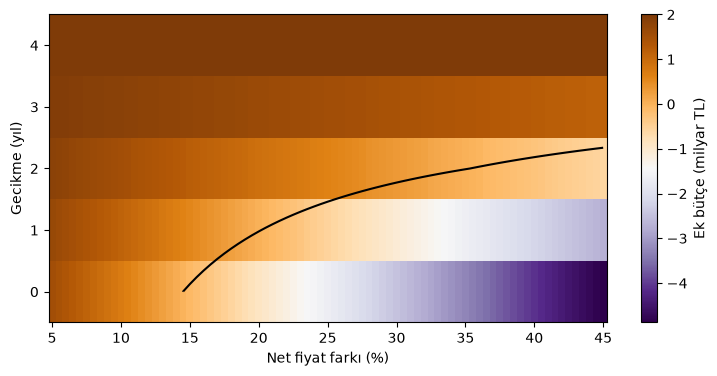

In [4]:
surface=budget.surface().pivot(index='delay',columns='discount_pct',values='total_bn')
fig,ax=plt.subplots(figsize=(9,4))
im=ax.pcolormesh(surface.columns,surface.index,surface,cmap='PuOr_r',shading='nearest')
ax.contour(surface.columns,surface.index,surface,levels=[0],colors='black')
ax.set(xlabel='Net fiyat farkı (%)',ylabel='Gecikme (yıl)')
fig.colorbar(im,ax=ax,label='Ek bütçe (milyar TL)');plt.show()

## 2. Kohort ve sanal hasta

Stabil, ilerlemiş ve ölüm durumlarını izleriz. Matris üssü analitik beklenen payları, rassal örnekleme ise 10.000 sanal kişinin yollarını verir. Bu kişiler gerçek hasta kaydı değildir.

{'delta_cost': 330596.28255539224, 'delta_qaly': 0.6728695284956459, 'icer': 491323.01070984156}


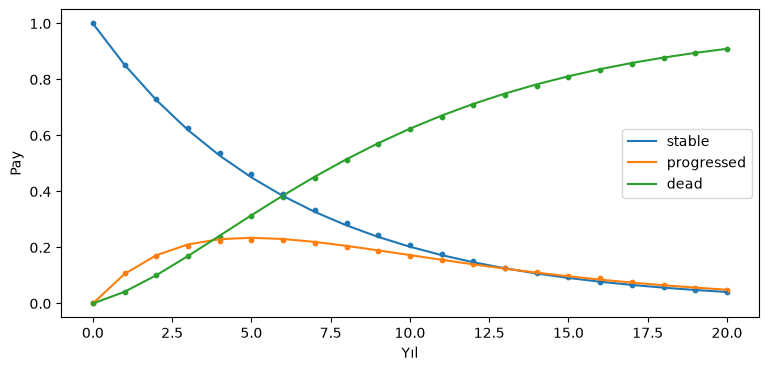

In [5]:
p=cohort.Cohort()
r=cohort.compare(p)
print({k:r[k] for k in ['delta_cost','delta_qaly','icer']})
trace=r['candidate']['trace']
micro,paths=cohort.simulate_people(p,n=10000,seed=20261012)
fig,ax=plt.subplots(figsize=(9,4))
for state in ['stable','progressed','dead']:
    line=ax.plot(trace.year,trace[state],label=state)[0]
    ax.scatter(micro.year,micro[state],s=10,color=line.get_color())
ax.set(xlabel='Yıl',ylabel='Pay');ax.legend();plt.show()

## 3. Parametre belirsizliği

Makaledeki 20.000 çekiliş ve sıralama korunur. Burada fiyat, klinik hız ve fayda ağırlıkları değişir; bu, sabit parametreli sanal hasta rastlantısallığından farklıdır.

In [6]:
rng=np.random.default_rng(20260922)
bd=budget.probabilistic(budget.Budget(),rng,20000)
cd=cohort.probabilistic(cohort.Cohort(),rng,20000)
curves=cohort.decision_curves(cd)
print('Tasarruf olasılığı:',(bd.total_bn<0).mean())
curves[curves.threshold==500000]

Tasarruf olasılığı: 0.6427


,threshold,probability,expected_nmb,evpi
25,500000.0,0.50325,4904.305261,50470.148387


## 4. Ar-Ge süreci

100 adayın her aşamadaki başarısı binomial çekilişle örneklenir. Bağımsız modelde beklenen onay sayısı 12,285'tir. Ortak risk korelasyonu ayrı beta-binomial modelde değerlendirilir.

rNPV (milyar TL): 0.8377923757417253
Ortalama onay sayısı: 12.2568
10 aday, bağımsız: 0.7303883358071035
10 aday, korelasyon 0.15: 0.5422735262693619


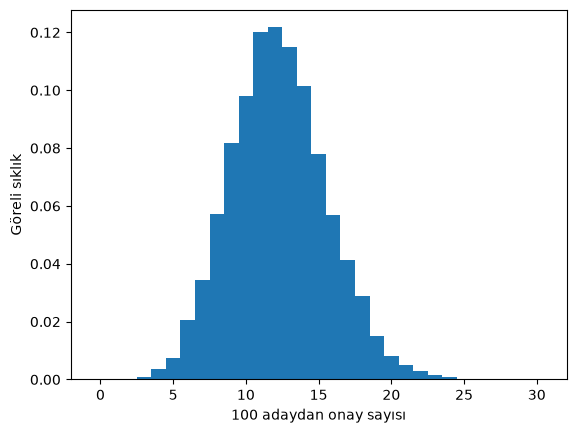

In [7]:
r=research.evaluate()
process=research.simulate_pipeline()
print('rNPV (milyar TL):',r['rnpv_bn'])
print('Ortalama onay sayısı:',process[:,-1].mean())
print('10 aday, bağımsız:',research.at_least_one(r['success'],10))
print('10 aday, korelasyon 0.15:',research.at_least_one(r['success'],10,.15))
plt.hist(process[:,-1],bins=np.arange(-.5,31.5),density=True)
plt.xlabel('100 adaydan onay sayısı');plt.ylabel('Göreli sıklık');plt.show()

## 5. Portföy

Beş proje ve bir platformun 64 bileşimi taranır. Amaç, bütçe ve platform koşulları altında beklenen net sağlık değerini artırmaktır. Ticari rNPV bu değere eklenmez.

In [8]:
print(portfolio.optimize())
print('Düşük eşik:',portfolio.optimize(threshold=500000))
print('Olumsuz senaryo:',portfolio.optimize(stress=True))
portfolio.projects()

{'selected': 'G;B;N1;P', 'spent_bn': 7.4, 'enmb_bn': 3.48513, 'feasible': True, 'platform': 1}


Düşük eşik: {'selected': 'G;B', 'spent_bn': 3.2, 'enmb_bn': 1.75, 'feasible': True, 'platform': 0}
Olumsuz senaryo: {'selected': 'G', 'spent_bn': 1.0, 'enmb_bn': 0.10249999999999981, 'feasible': True, 'platform': 0}


,id,name,investment_bn,probability,qaly,health_cost_bn,platform_eligible,platform_required
0,G,Kritik eşdeğer,1.0,0.90000,1000,-1.5,False,False
1,B,Biyobenzer,2.2,0.70000,1000,-4.0,False,False
2,R,Yeniden konumlandırma,1.3,0.45000,6000,1.5,True,False
3,N1,Faz I adayı,3.0,0.12285,50000,12.0,True,True
4,N2,Faz II adayı,2.5,0.18900,26000,8.0,True,True


## Kendi senaryonuz

Aşağıdaki fiyat farkını ve gecikmeyi değiştirip tekrar çalıştırın. Bu deterministik değişiklikler yukarıdaki sabit makale PSA dağılımlarını değiştirmez.

In [9]:
my_budget=replace(budget.Budget(),discount=.15)
budget.evaluate(my_budget,delay=1)['table']

,year,additional_patient_years,drug_delta_bn,monitor_delta_bn,programme_cost_bn,delta_cost_bn,cumulative_bn
0,0,0.0,0.00,0.00,1.5,1.50,1.50
1,1,0.0,-0.00,0.00,0.1,0.10,1.60
2,2,0.0,-0.00,0.00,0.1,0.10,1.70
3,3,20000.0,-0.30,0.04,0.1,-0.16,1.54
4,4,40000.0,-0.60,0.08,0.1,-0.42,1.12
5,5,50000.0,-0.75,0.10,0.1,-0.55,0.57
